In [1]:
# import the wandb libraries, for the plot

import wandb
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [2]:
# the orders of the distr value is ordinal and should be ordered as iid < non-iid_5 < non-iid_0.99 < non-iid_0.1
distributions = ["iid", "non-iid_5.0", "non-iid_0.99"]

In [3]:
# retrive all the runs from the project "FEDEXAI"
api = wandb.Api()
runs = api.runs("FEDEXAI")
# get the last run
runs is None, len(runs)


(False, 182)

In [19]:
run.config.keys()

dict_keys(['alpha', 'sweep', 'layers', 'dropout', 'momentum', 'batch_size', 'num_rounds', 'num_clients', 'dataset_name', 'hidden_units', 'local_epochs', 'class_weights', 'learning_rate'])

In [20]:
# create a dictionary to store the data
data = {}
for run in runs:
    # retrive the data from the run
    run_data = run.history()
    # retrive the name of the run
    run_name = run.name
    # print the dataset name that is in the run under the key "dataset_name"
    #print(run.config['dataset_name'])
    # configure the data in the dictionary inserting the dataset_name, 
    # the number of clients, the distribution and the f1 score

    data_dict = {
        "alpha": run.config['alpha'],
        "num_clients": run.config['num_clients'],
        "dataset_name": run.config['dataset_name'],
        "dropout": run.config['dropout'],
        "learning_rate": run.config['learning_rate'],
        "hidden"
        "momentum": run.config['momentum'],
        "num_rounds": run.config['num_rounds'],
        "batch_size": run.config['batch_size'],
        "local_epochs": run.config['local_epochs'],
        # and the score
        'hidden_units': run.config['hidden_units'],
        'layers': run.config['layers'],
        'num_rounds': run.config['num_rounds'],
        "test_f1_weighted": run.summary["test_f1_weighted"],
        "test_f1_macro": run.summary["test_f1_macro"],
    }
    data[run_name] = data_dict
    

In [21]:
# transform the dictionary in a pandas dataframe
df = pd.DataFrame(data.values()).T
df.columns = data.keys()
df = df.T
df.reset_index(inplace=True)
df.rename(columns={"index": "run_name"}, inplace=True)
df

,run_name,alpha,num_clients,dataset_name,dropout,learning_rate,hiddenmomentum,num_rounds,batch_size,local_epochs,hidden_units,layers,test_f1_weighted,test_f1_macro
0,ethereal-sound-366,5.0,12,diamond_1_hot,0.028699,0.234572,0.15103,30,64,3,87,1,0.741588,0.730429
1,noble-sunset-365,0.99,12,diamond_1_hot,0.043868,0.111692,0.253223,30,64,5,50,1,0.730646,0.713832
2,autumn-darkness-364,100000.0,12,diamond_1_hot,0.08735,0.085009,0.479772,30,64,5,75,3,0.771195,0.76213
3,sandy-water-363,10000.0,8,dry_bean,0.02766,0.353754,0.386677,10,4,3,74,2,0.929543,0.940443
4,smooth-dream-362,10000.0,16,dry_bean,0.002736,0.270475,0.161864,30,16,5,11,1,0.927723,0.93803
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
177,sage-darkness-157,0.99,4,adult_TargEncoded,0.009081,0.003604,0.843042,50,128,5,86,1,0.827369,0.745559
178,crisp-tree-156,0.5,16,adult_TargEncoded,0.085225,0.41315,0.004318,30,128,2,15,3,0.838158,0.764465
179,solar-forest-155,0.5,8,adult_TargEncoded,0.004031,0.149402,0.859422,50,128,2,82,2,0.657944,0.432195
180,genial-spaceship-154,0.5,4,adult_TargEncoded,0.011929,0.239989,0.739535,50,80,1,84,1,0.840812,0.762175


In [22]:
# how many different datasets are in the dataframe? (4)
# remove one_hot_Monks-3 from the list
print(df.dataset_name.unique())
df = df[df.dataset_name != "one_hot_Monks-3"]
df.dataset_name.unique()

['diamond_1_hot' 'dry_bean' 'adult_TargEncoded' 'one_hot_Monks-3']


array(['diamond_1_hot', 'dry_bean', 'adult_TargEncoded'], dtype=object)

In [23]:
# remap the alpha values into a string
# if alpha is > 1000, then it is "iid"
# if alpha is < 1000, then it is "non-iid" followed by the value of alpha
df["distr"] = df["alpha"].map(lambda x: "iid" if x > 1000 else f"non-iid_{x}")
# check the values
df.alpha.unique(), df.distr.unique()

/tmp/ipykernel_2834953/1630181759.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["distr"] = df["alpha"].map(lambda x: "iid" if x > 1000 else f"non-iid_{x}")


(array([5.0, 0.99, 100000.0, 10000.0, 0.5], dtype=object),
 array(['non-iid_5.0', 'non-iid_0.99', 'iid', 'non-iid_0.5'], dtype=object))

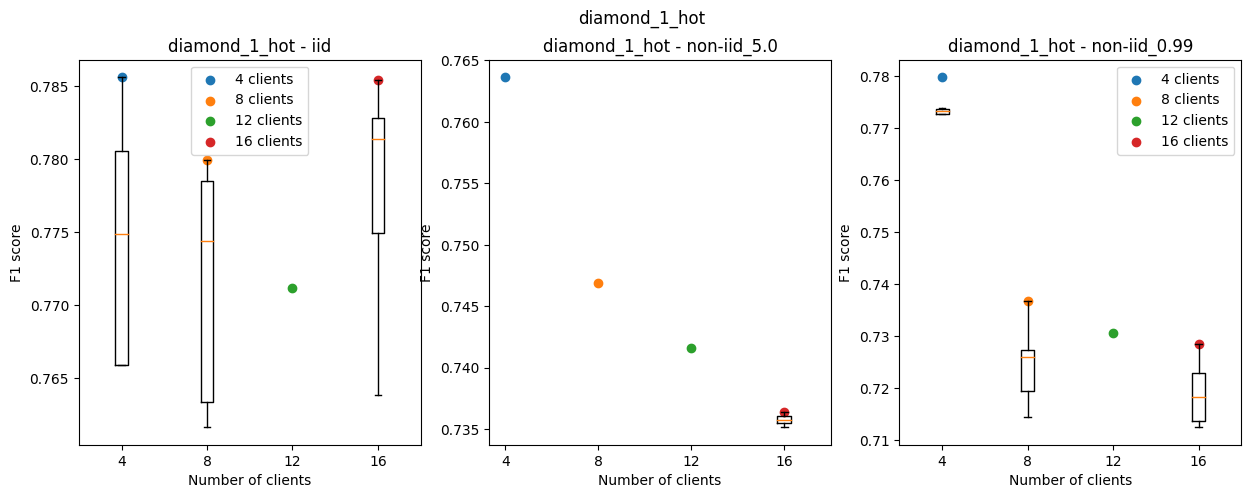

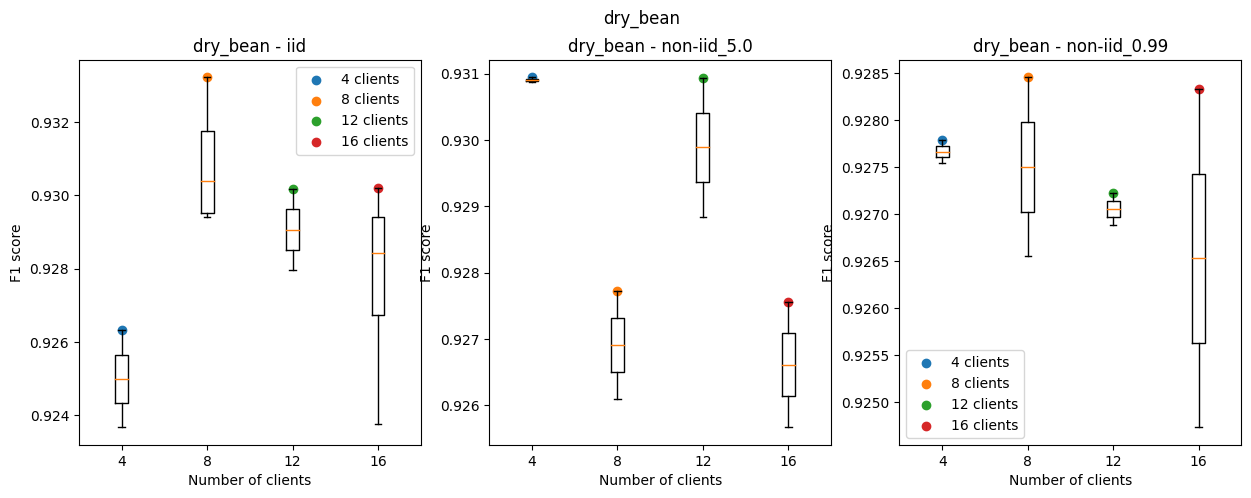

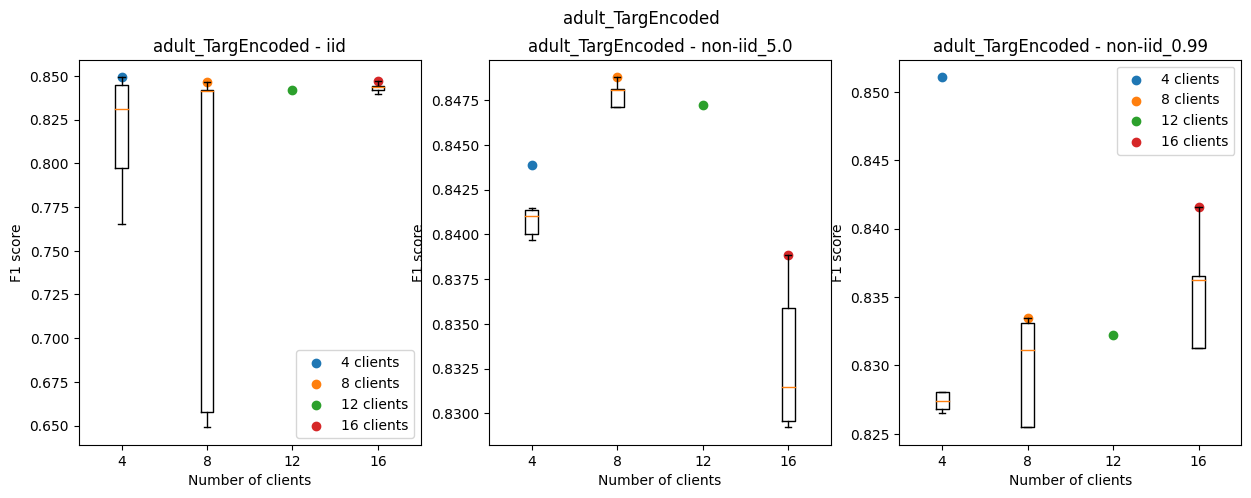

In [24]:

# for each dataset and distribution, plot the histogram of the f1 score (there should be at least 4 runs for each dataset and distribution)
# the title of the plot should be the dataset name and the distribution name
# at the positions 1, 2, 3, 4 of the x-axis, plot the f1 score of the runs with num_clients equal to 4, 8, 12, 16 respectively, since the runs are done with different random seeds, you should plot the mean and the standard deviation of the f1 score or directly the boxplot. plot it with low alpha value and as a scatter plot the max (if there is only one run, do not plot the boxplot, just the scatter plot)

for dataset in df.dataset_name.unique():
    fig, axs = plt.subplots(1, 3, figsize=(15, 5))
    for distr in distributions:    
        ax = axs[distributions.index(distr)]
        for j,num_clients in enumerate([4, 8, 12,16]):
            # select the data
            data_to_plot = df[(df.dataset_name == dataset) & (df.distr == distr) & (df.num_clients == num_clients)]
            if len(data_to_plot) <= 1:
                ax.scatter(j, data_to_plot.test_f1_weighted, label=f"{num_clients} clients")
            else:
                ax.boxplot(data_to_plot.test_f1_weighted, positions=[j], showfliers=False)
                ax.scatter(j, np.max(data_to_plot.test_f1_weighted), label=f"{num_clients} clients")
        ax.set_xticks(range(4))
        ax.set_xticklabels(["4", "8", "12", "16"])
        ax.set_xlabel("Number of clients")
        ax.set_ylabel("F1 score")
        ax.set_title(f"{dataset} - {distr}")
    axs[0].legend()
    # the title
    plt.suptitle(dataset)
    plt.legend()
    plt.show()



In [25]:
# the objective of this script is to plot the results of the wandb runs, 
# it will result in a table similar to the following:
'''\begin{table}[h]
    \centering
    \begin{tabular}{|c|c|c|c|c|}
        \hline
        \multirow{2}{*}{dataset name} & \multirow{2}{*}{\# clients} & \multicolumn{3}{c|}{distributions} \\ \cline{3-5}
                                      &                            & IID & non-IID (Medium) & non-IID (High) \\ \hline
        \multirow{4}{*}{Dry bean}     & 4 clients                  & f1\_1 & f1\_2 & f1\_3 \\ \cline{2-5}
                                      & 8 clients                  & f1\_1 & f1\_2 & f1\_3 \\ \cline{2-5}
                                      & 12 clients                 & f1\_1 & f1\_2 & f1\_3 \\ \cline{2-5}
                                      & 16 clients                 & f1\_1 & f1\_2 & f1\_3 \\ \hline
    \end{tabular}
    \caption{Distribution of clients and dataset variations for the datasets}
    \label{tab:HPScores}
\end{table}'''
table_header = '''
\\begin{table}[h]
    \\centering
    \\begin{tabular}{|c|c|c|c|c|}
        \\hline
        \\multirow{2}{*}{dataset name} & \\multirow{2}{*}{\\# clients} & \\multicolumn{3}{c|}{distributions} \\\\ \\cline{3-5}
                                    &                            & IID & non-IID (Medium) & non-IID (High) \\\\ \\hline'''
table_footer = ''' \end{tabular}
\caption{Distribution of clients and dataset variations for the datasets}
\label{tab:HPScores}
\end{table}'''

project_name = lambda x: "Dry bean" if x == "dry_bean" else "Adult" if x == "adult_TargEncoded" else "Diamond"

def create_table(data_f,dt_names):
    '''data_f is a dataframe with the following columns, dataset_name, num_clients, distribution, test_f1_weighted, test_f1_macro. It will return a string with the table to be printed in latex'''
    table = table_header
    for dt_name in dt_names:
        table += '\n'
        table += f'\\multirow{{4}}{{*}}{{{project_name(dt_name)}}} '
        for i in [4,8,12,16]:
            table += '    '*4 if i > 4 else '    ' 
            #table += f'& {i} clients & '
            table += f'& {i} & '
            for d in distributions:
                #print(dt_name,i,d)
                ## how many with this dataset, num_clients and distribution?
                #print("With this dataset, runs:",len(data_f[(data_f.dataset_name == dt_name)]))
                #print("With this dataset, num_clients:",len(data_f[(data_f.dataset_name == dt_name) & (data_f.num_clients == i)]))
                #print("With this dataset, num_clients and distribution:",len(data_f[(data_f.dataset_name == dt_name) & (data_f.num_clients == i) & (data_f.distr == d)])) 
                f1 = data_f[(data_f.dataset_name == dt_name) & 
                            (data_f.distr == d) & 
                            (data_f.num_clients == i)]["test_f1_weighted"]
                #print(d,f1, max(f1.values),np.mean(f1.values))
                table += f'{max(f1.values):.3f} ± {np.std(f1.values):.3f} (runs:{len(f1)})'
                table += ' & ' if d != distributions[-1] else ''
            table += ' \\\\ \\cline{2-5}\n'
        table += '\\hline\n'
    table += table_footer
    return table
print(create_table(df, 
                   dt_names=['dry_bean','adult_TargEncoded','diamond_1_hot']))



\begin{table}[h]
    \centering
    \begin{tabular}{|c|c|c|c|c|}
        \hline
        \multirow{2}{*}{dataset name} & \multirow{2}{*}{\# clients} & \multicolumn{3}{c|}{distributions} \\ \cline{3-5}
                                    &                            & IID & non-IID (Medium) & non-IID (High) \\ \hline
\multirow{4}{*}{Dry bean}     & 4 & 0.926 ± 0.001 (runs:2) & 0.931 ± 0.000 (runs:2) & 0.928 ± 0.000 (runs:2) \\ \cline{2-5}
                & 8 & 0.933 ± 0.002 (runs:4) & 0.928 ± 0.001 (runs:2) & 0.928 ± 0.001 (runs:2) \\ \cline{2-5}
                & 12 & 0.930 ± 0.001 (runs:2) & 0.931 ± 0.001 (runs:2) & 0.927 ± 0.000 (runs:2) \\ \cline{2-5}
                & 16 & 0.930 ± 0.002 (runs:4) & 0.928 ± 0.001 (runs:2) & 0.928 ± 0.002 (runs:2) \\ \cline{2-5}
\hline

\multirow{4}{*}{Adult}     & 4 & 0.849 ± 0.029 (runs:8) & 0.844 ± 0.002 (runs:6) & 0.851 ± 0.010 (runs:5) \\ \cline{2-5}
                & 8 & 0.846 ± 0.093 (runs:5) & 0.849 ± 0.005 (runs:5) & 0.833 ± 0.004 (runs:5) \\

In [44]:
# the objective of this script is to plot the results of the wandb runs, 
# it will result in a table similar to the following:
'''\begin{table}[h]
    \centering
    \begin{tabular}{|c|c|c|c|c|}
        \hline
        \multirow{2}{*}{dataset name} & \multirow{2}{*}{\# clients} & \multicolumn{3}{c|}{distributions} \\ \cline{3-5}
                                      &                            & IID & non-IID (Medium) & non-IID (High) \\ \hline
        \multirow{4}{*}{Dry bean}     & 4 clients                  & f1\_1 & f1\_2 & f1\_3 \\ \cline{2-5}
                                      & 8 clients                  & f1\_1 & f1\_2 & f1\_3 \\ \cline{2-5}
                                      & 12 clients                 & f1\_1 & f1\_2 & f1\_3 \\ \cline{2-5}
                                      & 16 clients                 & f1\_1 & f1\_2 & f1\_3 \\ \hline
    \end{tabular}
    \caption{Distribution of clients and dataset variations for the datasets}
    \label{tab:HPScores}
\end{table}'''
table_header = '''
\\begin{table}[h]
    \\centering
    \\begin{tabular}{|c|c|c|c|c|}
        \\hline
        \\multirow{2}{*}{dataset name} & \\multirow{2}{*}{\\# clients} & \\multicolumn{3}{c|}{distributions} \\\\ \\cline{3-5}
                                    &                            & IID &  \\makecell{non-IID \\\\ (Medium)} &  \\makecell{non-IID \\\\ (High)} \\\\ \\hline'''
table_footer = ''' \end{tabular}
\caption{Best Hyperparameters of BEST_HP for clients, distribution and dataset variations for the experiments}
\label{tab:bestBEST_HP}
\end{table}'''

project_name = lambda x: "Dry bean" if x == "dry_bean" else "Adult" if x == "adult_TargEncoded" else "Diamond"

def create_table(data_f,dt_names,hyp_param,std=False,as_int=False):
    '''data_f is a dataframe with the following columns, dataset_name, num_clients, distribution, test_f1_weighted, test_f1_macro. It will return a string with the table to be printed in latex'''
    table = table_header
    for dt_name in dt_names:
        table += '\n'
        table += f'\\multirow{{4}}{{*}}{{{project_name(dt_name)}}} '
        for i in [4,8,12,16]:
            table += '    '*4 if i > 4 else '    ' 
            #table += f'& {i} clients & '
            table += f'& {i} & '
            for d in distributions:
                valori = data_f[(data_f.dataset_name == dt_name) & 
                            (data_f.distr == d) & 
                            (data_f.num_clients == i)][hyp_param]
                #print(d,f1, max(f1.values),np.mean(f1.values))
                if as_int:
                    table += f'{max(valori.values):.0f}'
                    #print(as_int,f'{max(valori.values):.0f}')
                else:
                    table += f'{max(valori.values):.3f}'
                    #print(f'{max(valori.values):.3f}')
                if std==True:
                    table += '± {np.std(valori.values):.3f} (runs:{len(valori)})'
                
                table += ' & ' if d != distributions[-1] else ''
            table += ' \\\\ \\cline{2-5}\n'
        table += '\\hline\n'
    table  = table.replace("distributions"," ".join(hyp_param.split("_")))
    table += table_footer
    table = table.replace("BEST_HP", " ".join(hyp_param.split("_")))
    return table
for hp in ["layers","hidden_units","batch_size","local_epochs"]:
    print(create_table(df, 
                   dt_names=['dry_bean','adult_TargEncoded','diamond_1_hot'],
                   hyp_param=hp,
                   std=False,
                   as_int = True)
    )
for hp in ["learning_rate","dropout"]:
    print(create_table(df, 
                   dt_names=['dry_bean','adult_TargEncoded','diamond_1_hot'],
                   hyp_param=hp,
                   std=False)
    )



\begin{table}[h]
    \centering
    \begin{tabular}{|c|c|c|c|c|}
        \hline
        \multirow{2}{*}{dataset name} & \multirow{2}{*}{\# clients} & \multicolumn{3}{c|}{layers} \\ \cline{3-5}
                                    &                            & IID &  \makecell{non-IID \\ (Medium)} &  \makecell{non-IID \\ (High)} \\ \hline
\multirow{4}{*}{Dry bean}     & 4 & 1 & 2 & 2 \\ \cline{2-5}
                & 8 & 2 & 1 & 1 \\ \cline{2-5}
                & 12 & 2 & 3 & 2 \\ \cline{2-5}
                & 16 & 2 & 1 & 1 \\ \cline{2-5}
\hline

\multirow{4}{*}{Adult}     & 4 & 3 & 2 & 3 \\ \cline{2-5}
                & 8 & 2 & 3 & 2 \\ \cline{2-5}
                & 12 & 3 & 3 & 3 \\ \cline{2-5}
                & 16 & 2 & 2 & 2 \\ \cline{2-5}
\hline

\multirow{4}{*}{Diamond}     & 4 & 3 & 3 & 3 \\ \cline{2-5}
                & 8 & 3 & 1 & 2 \\ \cline{2-5}
                & 12 & 3 & 1 & 1 \\ \cline{2-5}
                & 16 & 3 & 2 & 2 \\ \cline{2-5}
\hline
 \end{tabular}
\caption{Best

In [18]:
df.columns

Index(['run_name', 'alpha', 'num_clients', 'dataset_name', 'dropout',
       'learning_rate', 'momentum', 'num_rounds', 'batch_size', 'local_epochs',
       'test_f1_weighted', 'test_f1_macro', 'distr'],
      dtype='object')